# Welcome Lab

<img src="../Workflow.png" alt="Workflow" width="600"/>


# Machine Learning Course 2025
## Welcome

### Why a reproducible environment matters
- ensures experiments can be repeated
- easier collaboration
- see [virtualenv](https://docs.python.org/3/library/venv.html) vs [conda](https://docs.conda.io/en/latest/)

### Setup Steps
1. Install conda or mamba.
2. Run `conda env create -f environment.yml`.
3. Activate with `conda activate machine-learning-course-2025`.
4. Launch JupyterLab with `jupyter lab` or use the classic notebook via `jupyter notebook`.

### Conda vs pip
**Advantages of conda**:
- Manages binary dependencies
- Handles environment isolation

**Disadvantages**:
- Larger downloads
- Slightly slower than `pip` for installs

### Reproducibility Formula
$$R = f(	ext{code}, 	ext{data}, 	ext{environment})$$

### Types of Data
- **Structured**: numeric and categorical tables.
- **Unstructured**: text, images, audio.
- **Time series**: ordered measurements over time.
- **Other domains**: graphs, spatial data, etc.


### Course Pipeline Overview
1. Prepare and clean data.
2. Preprocess features (scaling, encoding).
3. Train regression and classification models.
4. Evaluate using cross validation.
5. Deploy and monitor models.


In [1]:
# Display package versions
import sys, pandas as pd, numpy as np
print("Python", sys.version)
print("pandas", pd.__version__)

Python 3.11.5 | packaged by Anaconda, Inc. | (main, Sep 11 2023, 13:26:23) [MSC v.1916 64 bit (AMD64)]
pandas 2.0.3


Load and preview data:

In [4]:
import pandas as pd

In [7]:
df = pd.read_csv('../data/iris.csv')

In [ ]:
# Load example Iris dataset
import pandas as pd # Data Loading/Manipulation
df = pd.read_csv('../data/iris.csv')
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),class
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


In [19]:
df.info(), df.describe(), df.head(), df.tail(), df.sample(), df.shape, df.columns, df.index, df.dtypes, df.isnull().sum(), df.nunique(), df.value_counts(), df.corr(), df.cov()

<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   class              150 non-null    int64  
dtypes: float64(4), int64(1)
memory usage: 6.0 KB


(None,
        sepal length (cm)  sepal width (cm)  petal length (cm)  \
 count         150.000000        150.000000         150.000000   
 mean            5.843333          3.057333           3.758000   
 std             0.828066          0.435866           1.765298   
 min             4.300000          2.000000           1.000000   
 25%             5.100000          2.800000           1.600000   
 50%             5.800000          3.000000           4.350000   
 75%             6.400000          3.300000           5.100000   
 max             7.900000          4.400000           6.900000   
 
        petal width (cm)       class  
 count        150.000000  150.000000  
 mean           1.199333    1.000000  
 std            0.762238    0.819232  
 min            0.100000    0.000000  
 25%            0.300000    0.000000  
 50%            1.300000    1.000000  
 75%            1.800000    2.000000  
 max            2.500000    2.000000  ,
    sepal length (cm)  sepal width (cm)  peta

In [14]:
df.describe()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),class
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333,1.000000
std,0.828066,0.435866,1.765298,0.762238,0.819232
min,4.300000,2.000000,1.000000,0.100000,0.000000
25%,5.100000,2.800000,1.600000,0.300000,0.000000
50%,5.800000,3.000000,4.350000,1.300000,1.000000
75%,6.400000,3.300000,5.100000,1.800000,2.000000
max,7.900000,4.400000,6.900000,2.500000,2.000000


In [15]:
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),class
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


### Monitoring memory usage
Use pandas utilities to check how much memory the DataFrame consumes.

In [30]:
df.memory_usage(deep=True).sum()

np.int64(6132)

In [12]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   class              150 non-null    int64  
dtypes: float64(4), int64(1)
memory usage: 6.0 KB


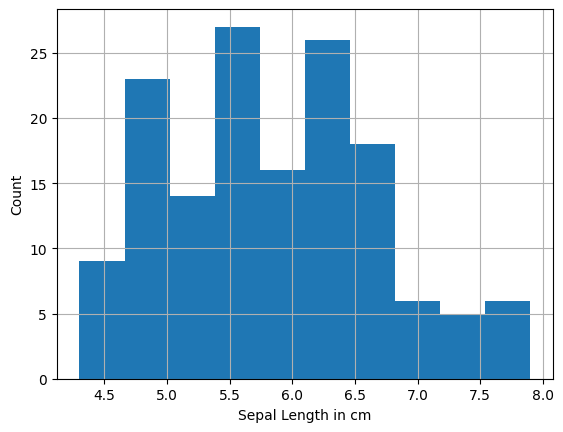

In [42]:
# Plot distribution of sepal length
import matplotlib.pyplot as plt
df['sepal length (cm)'].hist()
plt.ylabel('Count')
plt.xlabel("Sepal Length in cm")
plt.show()

### Quick data dashboard
Pairwise scatter plots can reveal relationships between features.

In [20]:
df['class'].value_counts()

class
0    50
1    50
2    50
Name: count, dtype: int64

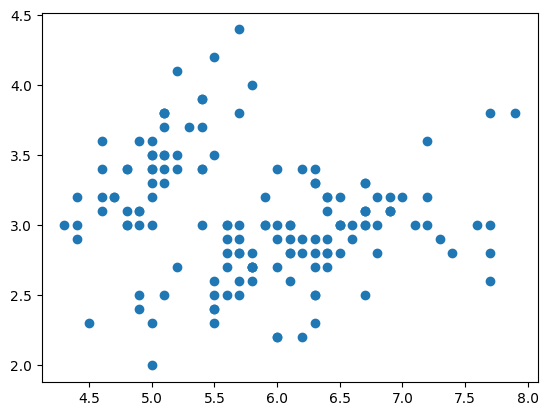

In [45]:
plt.scatter(df['sepal length (cm)'], df['sepal width (cm)'])

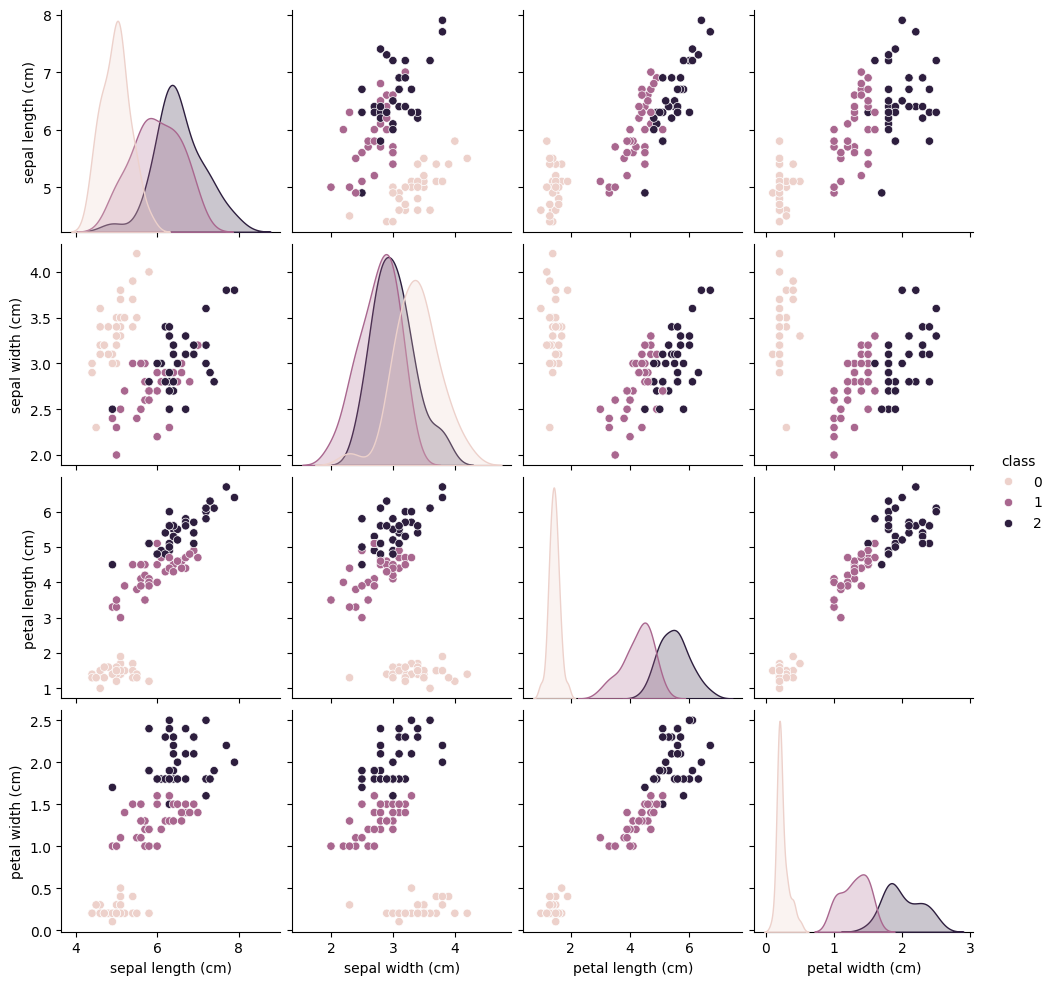

In [48]:
import seaborn as sns, matplotlib.pyplot as plt # Data Visualization
sns.pairplot(df.sample(100), hue='class')
plt.show()

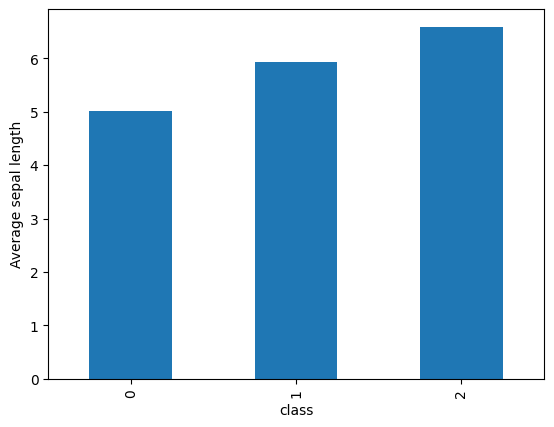

In [7]:
import matplotlib.pyplot as plt
df.groupby('class')['sepal length (cm)'].mean().plot(kind='bar', ylabel='Average sepal length')
plt.show()

### Framing a Machine Learning Problem
- Define the prediction target.
- Identify input features.
- Choose evaluation metrics.
- Decide how the model will be used.

### Usage Example

In [21]:
# Filter class 0 examples
df[df['class'] == 0].head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),class
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


### More Data Filtering with pandas and NumPy

In [22]:
# Boolean filtering with loc
filtered = df.loc[df['sepal length (cm)'] > 6, ['sepal length (cm)', 'class']]
filtered.head()

,sepal length (cm),class
50,7.0,1
51,6.4,1
52,6.9,1
54,6.5,1
56,6.3,1


In [54]:
# Selecting rows and columns by position with iloc
df.iloc[5:10, 2:4]

,petal length (cm),petal width (cm)
5,1.7,0.4
6,1.4,0.3
7,1.5,0.2
8,1.4,0.2
9,1.5,0.1


In [57]:
# Basic NumPy statistics
import numpy as np
lengths = df['sepal length (cm)'].values
print('Mean length:', np.mean(lengths))
print('Std dev:', np.std(lengths))

Mean length: 5.843333333333334
Std dev: 0.8253012917851409


In [70]:
np.where(lengths > lengths.mean(), 'long', 'short')

array(['short', 'short', 'short', 'short', 'short', 'short', 'short',
       'short', 'short', 'short', 'short', 'short', 'short', 'short',
       'short', 'short', 'short', 'short', 'short', 'short', 'short',
       'short', 'short', 'short', 'short', 'short', 'short', 'short',
       'short', 'short', 'short', 'short', 'short', 'short', 'short',
       'short', 'short', 'short', 'short', 'short', 'short', 'short',
       'short', 'short', 'short', 'short', 'short', 'short', 'short',
       'short', 'long', 'long', 'long', 'short', 'long', 'short', 'long',
       'short', 'long', 'short', 'short', 'long', 'long', 'long', 'short',
       'long', 'short', 'short', 'long', 'short', 'long', 'long', 'long',
       'long', 'long', 'long', 'long', 'long', 'long', 'short', 'short',
       'short', 'short', 'long', 'short', 'long', 'long', 'long', 'short',
       'short', 'short', 'long', 'short', 'short', 'short', 'short',
       'short', 'long', 'short', 'short', 'long', 'short', 'long', 'lo

In [ ]:
# Create a label using NumPy where
df['length_label'] = np.where(lengths > lengths.mean(), 'long', 'short')
df[['sepal length (cm)', 'length_label']].head()

In [28]:
df.columns

Index(['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)',
       'petal width (cm)', 'class'],
      dtype='object')

### Exercises & Further Reading
1. Explore different datasets from scikit-learn and load one into a Pandas DataFrame.
2. Use NumPy to compute the mean, median and standard deviation for numeric columns.
3. Filter the DataFrame to only include rows where the target matches a specific value.
4. Plot a histogram of a numeric feature with matplotlib.
5. Draw a line chart of the first feature across samples using matplotlib.
6. Visualize the relationship between two features using seaborn.scatterplot.
7. Create a pair plot of the DataFrame with seaborn.
8. Group by a categorical column with Pandas and plot the aggregated results using seaborn.barplot.
9. Save the cleaned DataFrame to CSV with Pandas.
10. [Pandas tutorial](https://pandas.pydata.org/docs/getting_started/index.html)
11. Filter rows where sepal width > 3 and compute the average petal length.
12. Sort the DataFrame by petal length in descending order.
13. Use `.iloc` to select the first three columns.
14. Use `.loc` to select rows 10 through 20 and columns "sepal length (cm)" and "class".
15. Create a NumPy array from a column and compute its variance.
16. Use `np.where` to add a label column based on petal width.
17. Plot the count of each label using seaborn.
18. Save the updated DataFrame to a new CSV file.

In [31]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   class              150 non-null    int64  
dtypes: float64(4), int64(1)
memory usage: 6.0 KB
